# Car Advisor MD — этап 1 (≈30%): от бизнес-задачи до бейзлайна

**Тема:** подбор автомобилей на основе машинного обучения и оценки рыночной цены.

Работа ведётся по методологии **CRISP-DM**. Этот ноутбук закрывает первые три фазы и делает первый шаг в четвёртую:

| Фаза CRISP-DM | Раздел | Статус |
|---|---|---|
| Business Understanding | [1](#1.-Business-Understanding) | ✅ |
| Data Understanding | [2](#2.-Data-Understanding) — 8 графиков EDA с выводами | ✅ |
| Data Preparation | [3](#3.-Data-Preparation) — очистка, пропуски, признаки, кодирование, масштабирование, train/test | ✅ |
| Modeling (бейзлайн) | [4](#4.-Бейзлайн-(бонус)) — три бейзлайна и первые метрики | ✅ |
| Modeling, Evaluation, Deployment | [5](#5.-Итоги-этапа-и-план) — план со сроками | ⏳ |

**Инструменты:** Python — pandas, matplotlib/seaborn, scikit-learn, SQLAlchemy. Код пайплайна вынесен в пакет `car_advisor/`, ноутбук его вызывает, поэтому результаты воспроизводятся командами `make data` и `make notebooks`.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from car_advisor import config, viz

viz.use_matplotlib_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def show(fig, name):
    # показать график и сохранить его в reports/figures — оттуда он попадает в отчёт
    fig.tight_layout()
    fig.savefig(config.FIGURES_DIR / f"{name}.png")
    plt.show()

## 1. Business Understanding

**Проблема.** На вторичном рынке Молдовы (основная площадка — 999.md) одинаковые автомобили продаются по ценам, которые различаются в разы. Покупатель не может быстро понять, справедлива ли цена: он переплачивает или попадается на «слишком дешёвые» объявления со скрытыми дефектами.

**Цель проекта.** Сервис, который:
1. оценивает **рыночную цену** автомобиля по его характеристикам;
2. говорит, насколько цена продавца **выше или ниже рынка**;
3. **подбирает** выгодные предложения под бюджет и требования покупателя.

**Пользователи:** покупатель, автоподборщик, автосалон (trade-in), лизинговая или страховая компания.

**Тип задачи машинного обучения**

| Подзадача | Тип ML | Как решается |
|---|---|---|
| Оценка рыночной цены | **регрессия** (обучение с учителем), целевая переменная — `price_eur` | основная модель проекта |
| Вердикт по цене продавца: дёшево / рыночная / завышена | производная от регрессии | сравнение цены продавца с оценкой модели и её интервалом |
| Подбор автомобилей | **рекомендация** (ранжирование) | фильтр по требованиям + сортировка по выгоде `(оценка − цена) / оценка` |

Почему регрессия, а не классификация: целевая переменная непрерывна, а готовых меток «дёшево/дорого» в данных нет — они как раз получаются из оценки регрессии.

**Метрики качества модели**
* **MAE, €** — средняя абсолютная ошибка в евро. Основная метрика выбора модели: бизнесу понятно «ошибаемся в среднем на N €».
* **MAPE, %** — средняя относительная ошибка. Ошибка в 1 000 € значит разное для машины за 3 000 € и за 30 000 €.
* **Доля оценок с ошибкой ≤ 20%** — как часто оценке можно доверять.
* **R²** — вспомогательная метрика: какую долю разброса цен объясняет модель.

**Критерии успеха (на тестовой выборке):** MAPE ≤ 25%; не меньше 60% оценок в пределах ±20% от цены; MAE хотя бы на 20% ниже лучшего бейзлайна (раздел 4).

**Ограничения:** в данных — цены объявлений (asking price), а не цены сделок; срез 2021 года; нет состояния, комплектации и истории ДТП.

## 2. Data Understanding

### 2.1 Источник данных и подключение к БД

Готового датасета у нас не было, поэтому выбран открытый датасет **[Cars for sale in Moldova](https://www.kaggle.com/datasets/alexandrududa/cars-moldova)** (Kaggle, лицензия CC0). Это объявления о продаже автомобилей с 999.md за 2021 год, то есть реальные данные именно того рынка, для которого делается проект. Почему не другие варианты:
* датасеты по рынкам США и Индии (*Used Cars Dataset*, *CarDekho*) — другой рынок, другие цены и марки;
* UCI *Automobile* — 205 строк 1985 года, только для учебных примеров.

Пайплайн данных: Kaggle API → `listings_raw` (сырые данные) → 11 правил качества → `listings` (очищенные) + `quality_issues` (журнал). База — SQLite через SQLAlchemy (PostgreSQL подключается переменной `DATABASE_URL`).

In [2]:
from sqlalchemy import inspect as sa_inspect, text
from car_advisor.data import database as db

source = json.loads(config.RAW_META.read_text(encoding="utf-8"))
print(f"Источник: {source['url']} | лицензия: {source['license']} | sha256: {source['sha256'][:16]}…")
engine = db.get_engine()
print("Таблицы БД:", sa_inspect(engine).get_table_names())
raw = db.read_table("listings_raw")
print(f"Сырых объявлений: {len(raw):,} строк × {len(db.LISTING_COLUMNS)} полей")
raw.head()

Источник: https://www.kaggle.com/datasets/alexandrududa/cars-moldova | лицензия: CC0: Public Domain | sha256: 3ae76b1813dda03d…
Таблицы БД: ['listings', 'listings_raw', 'quality_issues']
Сырых объявлений: 41,007 строк × 9 полей


,id,make,model,year,style,distance_km,engine_cc,fuel_type,transmission,price_eur,loaded_at
0,1,Toyota,Prius,2011,Hatchback,195000.0,1800.0,Hybrid,Automatic,7750.0,2026-10-06 13:57:00
1,2,Renault,Grand Scenic,2014,Universal,135000.0,1500.0,Diesel,Manual,8550.0,2026-10-06 13:57:00
2,3,Volkswagen,Golf,1998,Hatchback,1.0,1400.0,Petrol,Manual,2200.0,2026-10-06 13:57:00
3,4,Renault,Laguna,2012,Universal,110000.0,1500.0,Diesel,Manual,6550.0,2026-10-06 13:57:00
4,5,Opel,Astra,2006,Universal,200000.0,1600.0,Metan/Propan,Manual,4100.0,2026-10-06 13:57:00


### 2.2 Описание признаков: тип и шкала измерения

* **номинальная** шкала — категории без порядка (марка, топливо);
* **интервальная** — есть порядок и осмысленные разности, но нет естественного нуля (год выпуска);
* **шкала отношений** — есть абсолютный ноль, осмысленны отношения («вдвое больший пробег»).

Порядковых признаков (например, «состояние: отличное/хорошее/…») в датасете нет.

In [3]:
dictionary = pd.DataFrame([
    ("make", "Марка", "категориальный", "номинальная"),
    ("model", "Модель", "категориальный", "номинальная"),
    ("year", "Год выпуска", "числовой, дискретный", "интервальная"),
    ("style", "Тип кузова", "категориальный", "номинальная"),
    ("distance_km", "Пробег, км", "числовой, непрерывный", "отношений"),
    ("engine_cc", "Объём двигателя, см³", "числовой, непрерывный", "отношений"),
    ("fuel_type", "Тип топлива", "категориальный", "номинальная"),
    ("transmission", "Коробка передач", "категориальный, бинарный", "номинальная (дихотомическая)"),
    ("price_eur", "Цена, € — ЦЕЛЕВАЯ ПЕРЕМЕННАЯ", "числовой, непрерывный", "отношений"),
], columns=["признак", "описание", "тип", "шкала"]).set_index("признак")
dictionary["dtype"] = raw[dictionary.index].dtypes.astype(str)
dictionary["уникальных"] = raw[dictionary.index].nunique()
number = lambda c, v: f"{v:.0f}" if c == "year" else f"{v:,.0f}".replace(",", " ")
dictionary["min … max"] = [f"{number(c, raw[c].min())} … {number(c, raw[c].max())}" if pd.api.types.is_numeric_dtype(raw[c])
                           else f"чаще всего: {raw[c].mode()[0]}" for c in dictionary.index]
dictionary

,описание,тип,шкала,dtype,уникальных,min … max
признак,,,,,,
make,Марка,категориальный,номинальная,str,87,чаще всего: Volkswagen
model,Модель,категориальный,номинальная,str,829,чаще всего: E Class
year,Год выпуска,"числовой, дискретный",интервальная,int64,75,1900 … 2021
style,Тип кузова,категориальный,номинальная,str,12,чаще всего: Sedan
distance_km,"Пробег, км","числовой, непрерывный",отношений,float64,8935,0 … 100 000 000
engine_cc,"Объём двигателя, см³","числовой, непрерывный",отношений,float64,724,0 … 9 999
fuel_type,Тип топлива,категориальный,номинальная,str,6,чаще всего: Diesel
transmission,Коробка передач,"категориальный, бинарный",номинальная (дихотомическая),str,2,чаще всего: Manual
price_eur,"Цена, € — ЦЕЛЕВАЯ ПЕРЕМЕННАЯ","числовой, непрерывный",отношений,float64,1824,1 … 10 000 000


In [4]:
raw[["year", "distance_km", "engine_cc", "price_eur"]].describe(percentiles=[0.01, 0.5, 0.99]).T.round(0)

,count,mean,std,min,1%,50%,99%,max
year,41007.0,2008.0,8.0,1900.0,1986.0,2009.0,2020.0,2021.0
distance_km,41007.0,456735.0,4451897.0,0.0,0.0,168000.0,1959874.0,100000000.0
engine_cc,41007.0,1854.0,700.0,0.0,100.0,1800.0,4400.0,9999.0
price_eur,41007.0,9727.0,50439.0,1.0,600.0,6600.0,49900.0,10000000.0


**Вывод.** 9 полей объявления: 5 категориальных и 4 числовых. Уже по `describe` видны проблемы: год 1900, пробег 100 000 000 км, цена 1 € и 10 000 000 €, объём двигателя 0. Медиана при этом правдоподобна, значит «мусор» сидит в хвостах.

### 2.3 Пропуски

In [5]:
explicit = raw[db.LISTING_COLUMNS].isna().sum()
print(f"Явных пропусков (NaN): {int(explicit.sum())}")
hidden = pd.Series({
    "year = 1900 (заглушка года)": (raw["year"] == 1900).sum(),
    "distance_km = 0 или 1 км": raw["distance_km"].isin([0, 1]).sum(),
    "engine_cc = 0 у не-электромобиля": ((raw["engine_cc"] == 0) & (raw["fuel_type"] != "Electric")).sum(),
}, name="строк").to_frame()
hidden["доля"] = (hidden["строк"] / len(raw)).map("{:.2%}".format)
hidden

Явных пропусков (NaN): 0


,строк,доля
year = 1900 (заглушка года),30,0.07%
distance_km = 0 или 1 км,1698,4.14%
engine_cc = 0 у не-электромобиля,20,0.05%


**Вывод.** Явных пропусков нет: на 999.md поля обязательные. Но продавцы, которые не хотят указывать значение, ставят **заглушку**: год 1900, пробег 0 или 1 км. Это *скрытые пропуски* (≈4% строк). Если их не найти, модель выучит, что «пробег 1 км» бывает у 20-летних машин. Как мы их обрабатываем — в разделе 3.2.

### 2.4 Выбросы и ошибки ввода

In [6]:
age_raw = config.SNAPSHOT_YEAR - raw["year"]
checks = pd.Series({
    "Пробег < 1000 км у авто старше 3 лет": ((raw["distance_km"] < 1000) & (age_raw >= 3)).sum(),
    "Пробег > 1 000 000 км": (raw["distance_km"] > 1_000_000).sum(),
    "Объём двигателя 90–500 «см³» (не электро)": (raw["engine_cc"].between(90, 499) & (raw["fuel_type"] != "Electric")).sum(),
    "Цена < 300 €": (raw["price_eur"] < 300).sum(),
    "Цена > 250 000 €": (raw["price_eur"] > 250_000).sum(),
    "Точные дубликаты объявлений": raw.duplicated(subset=db.LISTING_COLUMNS).sum(),
}, name="строк").to_frame()

# Для сравнения: что убрал бы формальный метод IQR (1.5 × межквартильный размах) по цене
q1, q3 = raw["price_eur"].quantile([0.25, 0.75])
iqr_out = raw[raw["price_eur"] > q3 + 1.5 * (q3 - q1)]
print(f"IQR пометил бы {len(iqr_out):,} цен ({len(iqr_out) / len(raw):.1%}) выше {q3 + 1.5 * (q3 - q1):,.0f} €. Самые частые марки среди них:")
print(iqr_out["make"].value_counts().head(6).to_string())
checks

IQR пометил бы 2,287 цен (5.6%) выше 25,125 €. Самые частые марки среди них:
make
Mercedes    534
BMW         471
Audi        191
Porsche     176
Lexus       144
Toyota      137


,строк
Пробег < 1000 км у авто старше 3 лет,3539
Пробег > 1 000 000 км,623
Объём двигателя 90–500 «см³» (не электро),957
Цена < 300 €,23
Цена > 250 000 €,2
Точные дубликаты объявлений,3743


**Вывод.** Выбросы здесь — это **ошибки ввода**, и у каждой своя природа:
* объём двигателя 200 «см³» — на самом деле 2.0 л (ввод в литрах × 100). Такие значения можно **исправить**, а не удалять;
* пробег 9 999 999 км и 100 000 000 км — физически невозможен;
* цена 490 000 € за KIA Sportage 2018 — судя по всему, цена в **леях**, а не в евро;
* ≈9% объявлений — точные дубликаты (повторные публикации).

Формальный метод IQR здесь не подходит: он пометил бы ≈5.6% цен, и это в основном **реальные** дорогие Mercedes, BMW, Porsche, Lexus. Поэтому вместо IQR мы используем правила предметной области: цену сравниваем с медианой *той же марки, модели и года*.

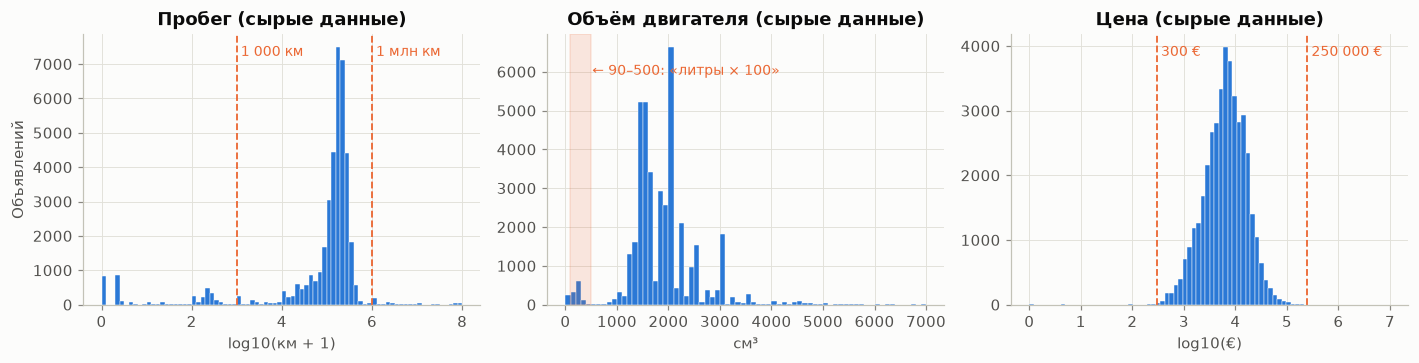

In [7]:
# Г2. Сырые данные: где сидят заглушки и ошибки
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(np.log10(raw["distance_km"] + 1), bins=80, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
for x, label in [(3, "1 000 км"), (6, "1 млн км")]:
    axes[0].axvline(x, color=viz.SERIES[1], linewidth=1.2, linestyle="--")
    axes[0].text(x, axes[0].get_ylim()[1] * 0.92, " " + label, color=viz.SERIES[1], fontsize=9)
axes[0].set(title="Пробег (сырые данные)", xlabel="log10(км + 1)", ylabel="Объявлений")

axes[1].hist(raw["engine_cc"].clip(upper=7000), bins=70, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
axes[1].axvspan(90, 500, color=viz.SERIES[1], alpha=0.15)
axes[1].text(520, axes[1].get_ylim()[1] * 0.85, "← 90–500: «литры × 100»", color=viz.SERIES[1], fontsize=9)
axes[1].set(title="Объём двигателя (сырые данные)", xlabel="см³")

axes[2].hist(np.log10(raw["price_eur"]), bins=80, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
for x, label in [(np.log10(300), "300 €"), (np.log10(250_000), "250 000 €")]:
    axes[2].axvline(x, color=viz.SERIES[1], linewidth=1.2, linestyle="--")
    axes[2].text(x, axes[2].get_ylim()[1] * 0.92, " " + label, color=viz.SERIES[1], fontsize=9)
axes[2].set(title="Цена (сырые данные)", xlabel="log10(€)")
show(fig, "eda_02_raw_outliers")

**Вывод (Г2).** Ошибки видны прямо на гистограммах: столбик у нуля и хвост правее 1 млн км у пробега, кластер 100–500 «см³» у объёма двигателя (это литры × 100), единичные цены в 1 € и 10 млн €. Пороги правил качества (пунктир) отделяют именно эти артефакты и не задевают основную массу данных.

### 2.5 Распределения (после очистки)

Дальше работаем с очищенной таблицей `listings`. Как она получена — раздел 3.1.

Очищенных объявлений (без отложенных «новых»): 31,298


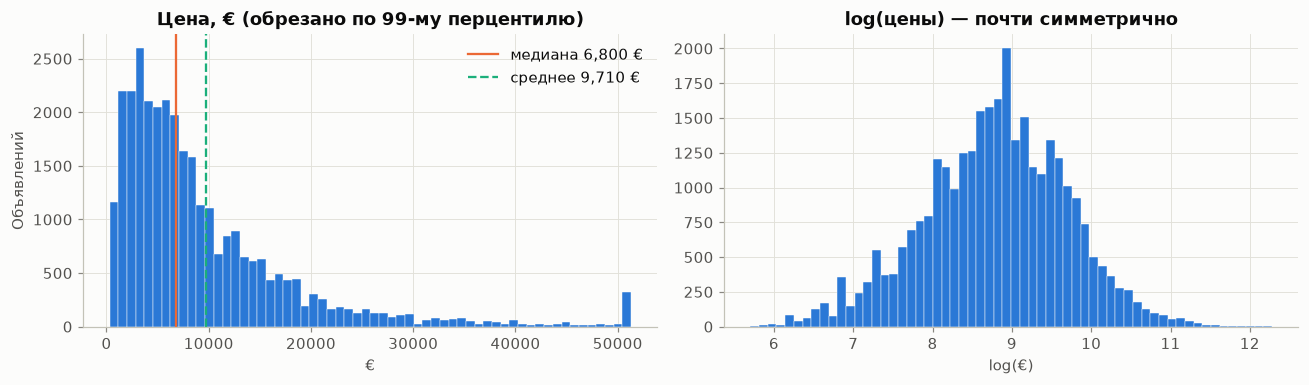

Асимметрия (skewness): цена 4.17, log(цены) -0.17


In [8]:
from car_advisor.ml.features import FeatureBuilder, CAT_FEATURES, NUM_FEATURES, FEATURE_LABELS

df = db.read_table("listings")
feats = FeatureBuilder().transform(df)
df["age"], df["km_per_year"] = feats["age"], feats["km_per_year"]
df["log_price"] = np.log(df["price_eur"])
print(f"Очищенных объявлений (без отложенных «новых»): {len(df):,}")

# Г1. Распределение целевой переменной
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(df["price_eur"].clip(upper=df["price_eur"].quantile(0.99)), bins=60, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
axes[0].axvline(df["price_eur"].median(), color=viz.SERIES[1], linewidth=1.5, label=f"медиана {df['price_eur'].median():,.0f} €")
axes[0].axvline(df["price_eur"].mean(), color=viz.SERIES[2], linewidth=1.5, linestyle="--", label=f"среднее {df['price_eur'].mean():,.0f} €")
axes[0].set(title="Цена, € (обрезано по 99-му перцентилю)", xlabel="€", ylabel="Объявлений"); axes[0].legend()
axes[1].hist(df["log_price"], bins=60, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
axes[1].set(title="log(цены) — почти симметрично", xlabel="log(€)")
show(fig, "eda_01_price_distribution")
print(f"Асимметрия (skewness): цена {df['price_eur'].skew():.2f}, log(цены) {df['log_price'].skew():.2f}")

**Вывод (Г1).** Цена сильно скошена вправо (асимметрия ≈ 4.2): среднее (~9 700 €) заметно выше медианы (6 800 €) из-за немногих дорогих машин. После логарифмирования распределение почти симметрично (асимметрия ≈ −0.2). Поэтому модели будем обучать на **log(цены)**: ошибка станет относительной, и дорогие машины не будут доминировать в функции потерь.

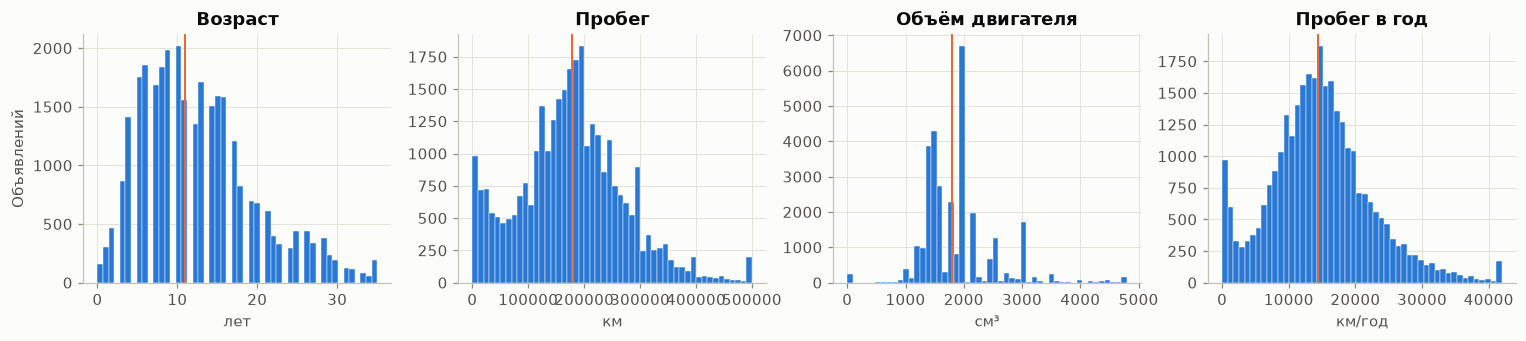

,age,distance_km,engine_cc,km_per_year
медиана,11.00,178722.00,1800.0,14375.00
асимметрия,0.85,0.98,1.7,2.82


In [9]:
# Г3. Распределения числовых признаков
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, col, xlabel in zip(axes, NUM_FEATURES, ["лет", "км", "см³", "км/год"]):
    ax.hist(df[col].clip(upper=df[col].quantile(0.995)), bins=50, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
    ax.axvline(df[col].median(), color=viz.SERIES[1], linewidth=1.3)
    ax.set(title=FEATURE_LABELS[col], xlabel=xlabel)
axes[0].set_ylabel("Объявлений")
show(fig, "eda_03_numeric_distributions")
pd.DataFrame({"медиана": df[NUM_FEATURES].median(), "асимметрия": df[NUM_FEATURES].skew().round(2)}).T

**Вывод (Г3).** Типичная машина на рынке — около 11 лет, 180 тыс. км пробега, 1.8 л. Все признаки скошены вправо, сильнее всего пробег в год (асимметрия 2.8) и объём двигателя (пики на стандартных моторах 1.4, 1.5, 1.6 и 2.0 л). Признаки измеряются в разных единицах и масштабах, от десятков лет до сотен тысяч км. Для линейной модели их нужно **масштабировать**, деревьям это не нужно (раздел 3.5).

### 2.6 Связь признаков с ценой

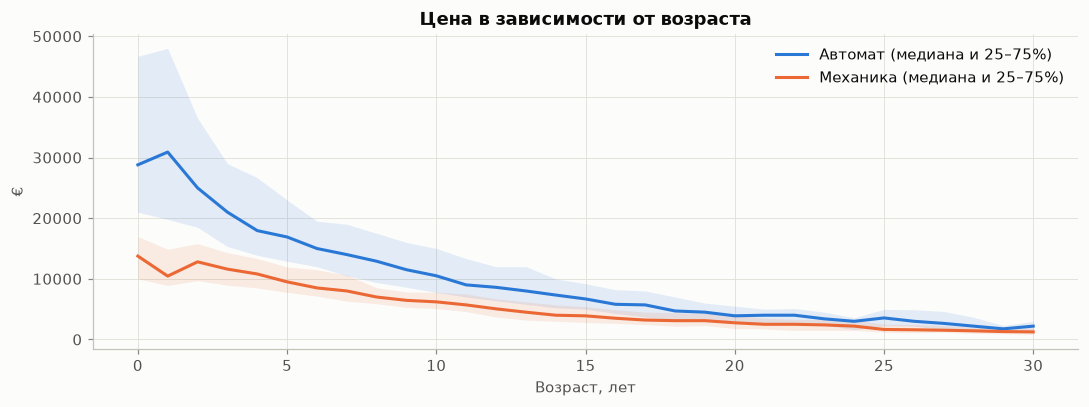

In [10]:
# Г4. Амортизация: цена в зависимости от возраста
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (trans, label) in enumerate([("Automatic", "Автомат"), ("Manual", "Механика")]):
    part = df[(df["transmission"] == trans) & (df["age"] <= 30)]
    s = part.groupby("age")["price_eur"].median()
    q = part.groupby("age")["price_eur"].quantile([0.25, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color=viz.SERIES[i], alpha=0.12, linewidth=0)
    ax.plot(s.index, s.values, color=viz.SERIES[i], linewidth=2, label=f"{label} (медиана и 25–75%)")
ax.set(title="Цена в зависимости от возраста", xlabel="Возраст, лет", ylabel="€"); ax.legend()
show(fig, "eda_04_price_vs_age")

**Вывод (Г4).** Возраст — главный фактор цены (корреляция Спирмена с log(цены) −0.79). Зависимость **нелинейная**: за первые 10 лет машина теряет ~55–65% цены, после ~20 лет кривая выходит на плато. Автомат дороже механики во всех возрастах, но разрыв сокращается к старым машинам. Вывод для модели: возраст нужен в нелинейной форме (сплайны или деревья), и полезны взаимодействия возраста с другими признаками.

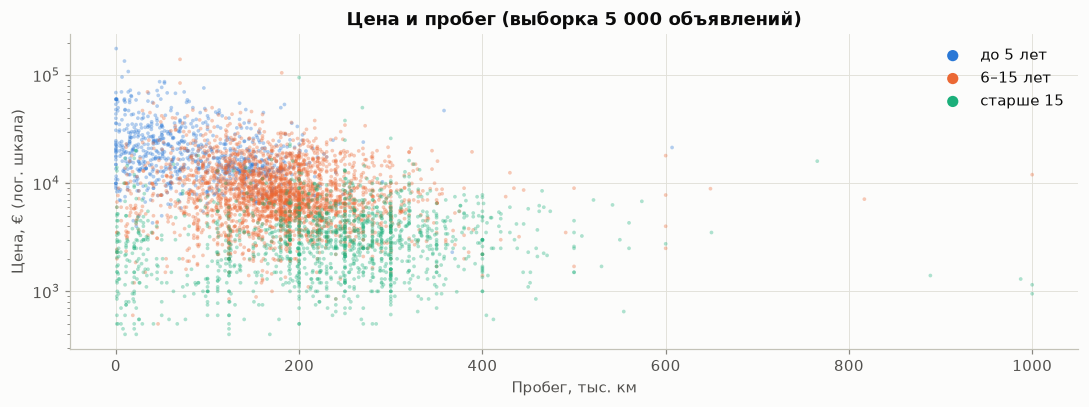

Корреляция Спирмена «пробег — log(цены)» внутри возрастных групп:
age
(-1, 5]     -0.31
(5, 10]     -0.09
(10, 15]     0.13
(15, 20]     0.21
(20, 100]    0.22


In [11]:
# Г5. Цена и пробег — с учётом возраста
sample = df.sample(5000, random_state=config.RANDOM_STATE)
groups = pd.cut(sample["age"], [-1, 5, 15, 100], labels=["до 5 лет", "6–15 лет", "старше 15"])
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, g in enumerate(groups.cat.categories):
    part = sample[groups == g]
    ax.scatter(part["distance_km"] / 1000, part["price_eur"], s=6, alpha=0.35, color=viz.SERIES[i], edgecolors="none", label=g)
ax.set(yscale="log", title="Цена и пробег (выборка 5 000 объявлений)", xlabel="Пробег, тыс. км", ylabel="Цена, € (лог. шкала)")
for h in ax.legend(markerscale=3).legend_handles:
    h.set_alpha(1)
show(fig, "eda_05_price_vs_mileage")
by_age = df.groupby(pd.cut(df["age"], [-1, 5, 10, 15, 20, 100]), observed=True)[["log_price", "distance_km"]] \
    .apply(lambda g: g.corr("spearman").iloc[0, 1]).round(2)
print("Корреляция Спирмена «пробег — log(цены)» внутри возрастных групп:"); print(by_age.to_string())

**Вывод (Г5).** В целом пробег связан с ценой отрицательно (ρ ≈ −0.35), но цвета показывают, что эту связь в основном объясняет **возраст**: облака разных возрастов лежат на разной высоте. Внутри групп картина другая. У машин до 5 лет пробег снижает цену (ρ ≈ −0.31), а у машин старше 10 лет связь даже *положительная*: больше ездят на дорогих дизельных и премиальных машинах. Это **конфаундинг** (смешение эффектов). Пробег нельзя оценивать отдельно от возраста, поэтому мы добавляем признак «пробег в год», а в следующем этапе возьмём модели, которые учат взаимодействия.

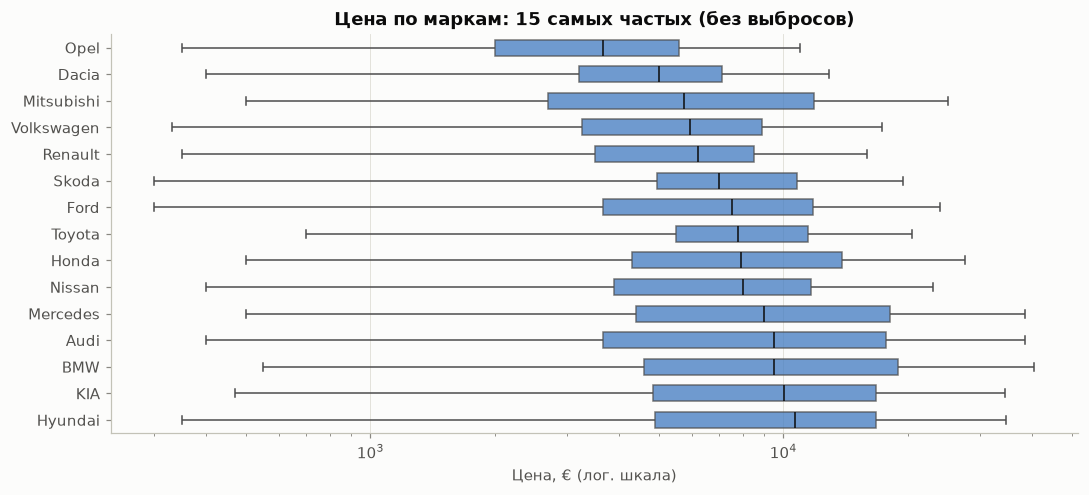

In [12]:
# Г6. Марка задаёт уровень цены
top = df["make"].value_counts().head(15).index
order = df[df["make"].isin(top)].groupby("make")["price_eur"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.boxplot(data=df[df["make"].isin(top)], y="make", x="price_eur", order=order, ax=ax, color=viz.SERIES[0],
            showfliers=False, width=0.6, boxprops={"alpha": 0.75}, medianprops={"color": viz.INK})
ax.set(xscale="log", title="Цена по маркам: 15 самых частых (без выбросов)", xlabel="Цена, € (лог. шкала)", ylabel="")
show(fig, "eda_06_price_by_make")

**Вывод (Г6).** Медианы марок различаются втрое: от ~3 650 € (Opel) до ~10 700 € (Hyundai). Порядок отражает не только «престиж», но и возраст парка: KIA и Hyundai на рынке моложе, чем Mercedes и BMW, поэтому их медиана выше. Это снова смешение с возрастом, и модель должна учитывать марку и возраст **вместе**. Внутри каждой марки разброс огромный (ящики перекрываются), так что одной марки для оценки мало.

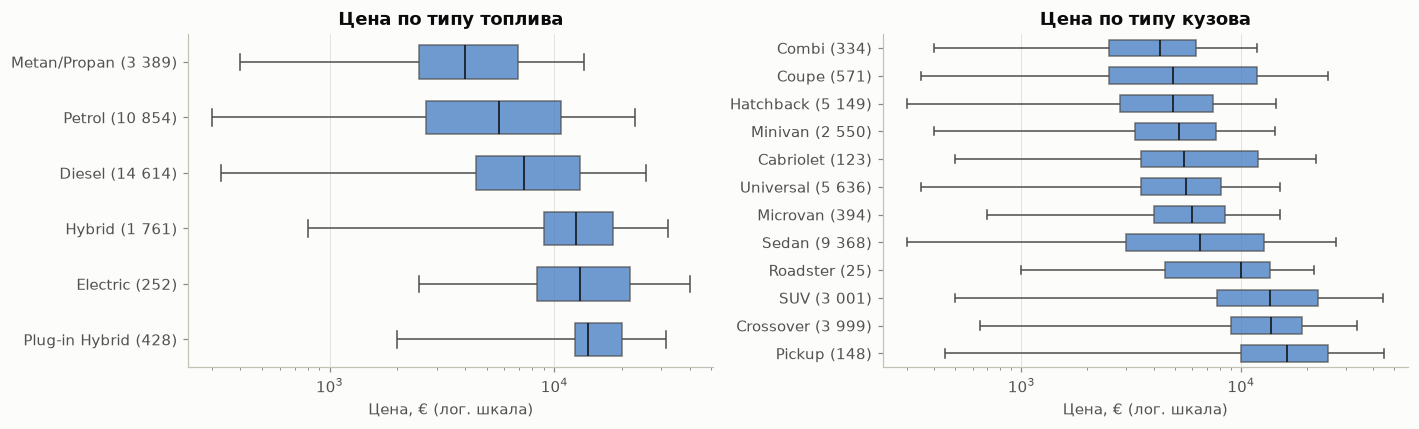

In [13]:
# Г7. Цена по типу топлива и типу кузова
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in [(axes[0], "fuel_type", "Цена по типу топлива"), (axes[1], "style", "Цена по типу кузова")]:
    order = df.groupby(col)["price_eur"].median().sort_values().index
    sns.boxplot(data=df, y=col, x="price_eur", order=order, ax=ax, color=viz.SERIES[0], showfliers=False,
                width=0.6, boxprops={"alpha": 0.75}, medianprops={"color": viz.INK})
    counts = df[col].value_counts()
    ax.set_yticklabels([f"{c} ({counts[c]:,})".replace(",", " ") for c in order])
    ax.set(xscale="log", title=title, xlabel="Цена, € (лог. шкала)", ylabel="")
show(fig, "eda_07_price_by_fuel_style")

**Вывод (Г7).** Гибриды и электромобили в среднем вдвое дороже бензиновых, но они и моложе (медианный возраст 5–7 лет против 13). Газ (Metan/Propan) — самый дешёвый сегмент, это старые переоборудованные машины. Среди кузовов дороже всего SUV, Crossover и Pickup. Видна сильная **несбалансированность категорий**: Electric — 0.8% объявлений, Roadster — 25 штук. При кодировании редкие значения нужно объединять (раздел 3.5).

### 2.7 Корреляции

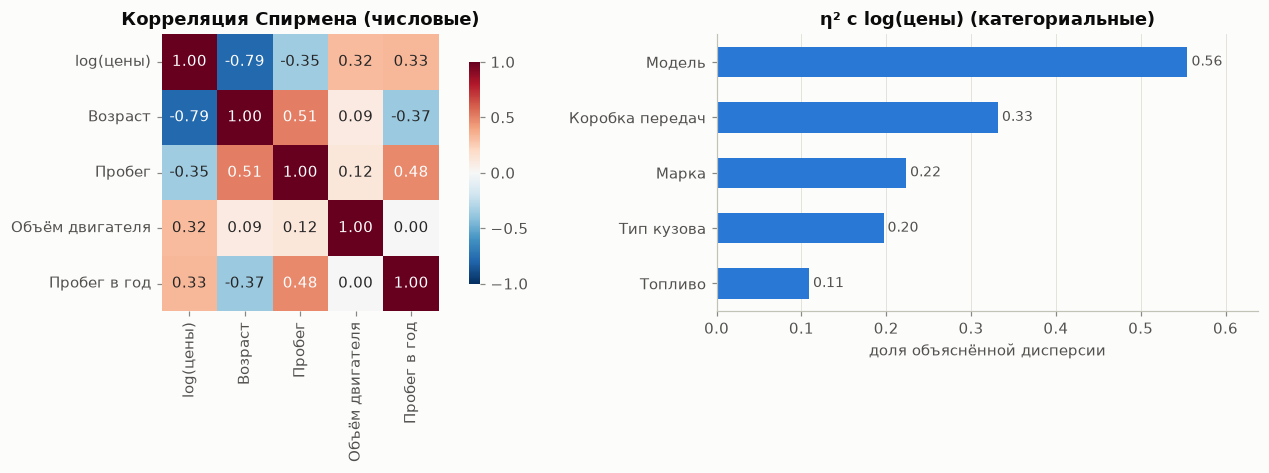

In [14]:
# Г8. Связи: числовые признаки (Спирмен) и категориальные (η² — доля разброса log(цены) между группами)
num_corr = df[["log_price"] + NUM_FEATURES].corr(method="spearman")


def eta_squared(cat):
    g = df.groupby(cat)["log_price"]
    return float((g.size() * (g.mean() - df["log_price"].mean()) ** 2).sum() / ((df["log_price"] - df["log_price"].mean()) ** 2).sum())


eta = pd.Series({FEATURE_LABELS[c]: eta_squared(c) for c in CAT_FEATURES}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
labels = ["log(цены)"] + [FEATURE_LABELS[c] for c in NUM_FEATURES]
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], square=True,
            xticklabels=labels, yticklabels=labels, cbar_kws={"shrink": 0.8})
axes[0].set_title("Корреляция Спирмена (числовые)")
axes[1].barh(eta.index, eta.values, color=viz.SERIES[0], height=0.55)
for i, v in enumerate(eta.values):
    axes[1].text(v, i, f" {v:.2f}", va="center", fontsize=9, color=viz.INK_SECONDARY)
axes[1].set(title="η² с log(цены) (категориальные)", xlabel="доля объяснённой дисперсии"); axes[1].grid(axis="y", visible=False)
axes[1].margins(x=0.15)
show(fig, "eda_08_correlations")

**Вывод (Г8).**
* Из числовых признаков сильнее всего с ценой связан **возраст** (ρ = −0.79). Пробег (−0.35), пробег в год (+0.33) и объём двигателя (+0.32) связаны умеренно.
* Возраст и пробег коррелируют между собой (ρ = 0.51), это мультиколлинеарность. Признак «пробег в год» с возрастом связан слабее (−0.37) и несёт новую информацию: интенсивность эксплуатации.
* Из категориальных признаков больше всего объясняет **модель** (η² = 0.56). Но у неё ≈900 значений, и η² для признаков с высокой кардинальностью завышен. Дальше идут КПП (0.33) и марка (0.22).
* Сильных линейных связей между «независимыми» числовыми признаками нет (|ρ| ≤ 0.51), так что ни один признак не дублирует другой полностью.

### 2.8 Итоги Data Understanding

1. Данные **реальные и открытые** (41 007 объявлений), но «грязные»: дубликаты, скрытые пропуски (заглушки), ошибки единиц измерения, невозможные значения.
2. Целевая переменная скошена → обучаем на **log(цены)**.
3. Главный фактор — **возраст**, и зависимость от него нелинейная. Пробег и марка смешаны с возрастом (конфаундинг), поэтому нужны модели с взаимодействиями.
4. **Модель** авто — самый информативный категориальный признак, но с высокой кардинальностью (≈900 значений) → нужно специальное кодирование.
5. В данных нет состояния, комплектации и истории ДТП — это верхняя граница достижимой точности.

## 3. Data Preparation

### 3.1 Очистка данных

11 правил качества сформулированы по итогам раздела 2 и реализованы в `car_advisor/data/quality.py`. Каждое удаление или исправление записывается в таблицу `quality_issues`: по журналу видно, какая строка и по какому правилу изменена.

In [15]:
report = json.loads(config.QUALITY_REPORT_JSON.read_text(encoding="utf-8"))
print(f"Было {report['rows_raw']:,} → стало {report['rows_clean']:,} ({report['rows_clean'] / report['rows_raw']:.1%}); "
      f"для обучения {report['rows_market']:,}, отложено как «новые» объявления {report['rows_holdout']:,}")
with engine.connect() as con:
    journal = pd.read_sql(text(
        "SELECT rule, action, COUNT(*) AS rows, MIN(details) AS example "
        "FROM quality_issues GROUP BY rule, action ORDER BY rows DESC"), con)
journal["rule"] = journal["rule"].map(lambda r: next(x["title"] for x in report["rules"] if x["code"] == r))
journal

Было 41,007 → стало 32,945 (80.3%); для обучения 31,298, отложено как «новые» объявления 1,647


,rule,action,rows,example
0,Точный дубликат объявления,drop,3743,повтор уже опубликованного объявления
1,Пробег < 1000 км у авто старше 3 лет (заглушка),drop,3230,"0 км, год 1980"
2,Объём двигателя указан в литрах×100 (200 → 200...,repair,915,100 → 1000
3,"Пробег больше 1,000,000 км",drop,582,"1,000,008 км"
4,Цена отличается от медианы марки/модели/года б...,drop,312,цена = 0.06 × медианы группы
5,Год выпуска вне диапазона 1980–2021,drop,141,1900
6,Объём двигателя у электромобиля (обнулён),repair,120,100 → 0
7,Объём двигателя вне 500–7000 см³,drop,29,0 см³
8,"Цена вне диапазона 300–250,000 €",drop,25,1 €


**Вывод.** Удалено 8 062 строки (19.7%), исправлено 1 035 значений. Самые массовые проблемы — дубликаты (3 743) и пробег-заглушка (3 230). Объём двигателя «в литрах × 100» **исправлен** (× 10), а не удалён: так сохранено 915 строк с корректной в остальном информацией.

### 3.2 Обработка пропусков

| Что | Стратегия | Почему |
|---|---|---|
| Явные пропуски (NaN) | правило `missing_values`: удаление | в этом датасете их 0, но правило нужно для новых данных |
| Год 1900 | удаление (правило «год вне 1980–2021») | год — главный признак, восстановить его по другим полям надёжно нельзя |
| Пробег 0–1 км у авто старше 3 лет | удаление | заполнение медианой «по возрасту» придумало бы значение одного из ключевых признаков; после удаления остаётся 80% данных, этого достаточно |
| Объём двигателя 0 у не-электромобиля | удаление (вне 500–7000 см³) | 20 строк |
| Объём двигателя у электромобиля | **заполнение константой 0** | у электромобиля объёма нет по смыслу |
| Неизвестная категория в новых данных | кодировщики с `handle_unknown` | модель не падает на модели авто, которой не было в train (раздел 3.5) |

Проверим, что после очистки не осталось ни явных, ни скрытых пропусков:

In [16]:
assert df[db.LISTING_COLUMNS].isna().sum().sum() == 0
left = {
    "NaN": int(df[db.LISTING_COLUMNS].isna().sum().sum()),
    "год < 1980": int((df["year"] < config.MIN_YEAR).sum()),
    "пробег < 1000 км у авто старше 3 лет": int(((df["distance_km"] < 1000) & (df["age"] >= 3)).sum()),
    "объём 0 у не-электро": int(((df["engine_cc"] == 0) & (df["fuel_type"] != "Electric")).sum()),
}
left

{'NaN': 0,
 'год < 1980': 0,
 'пробег < 1000 км у авто старше 3 лет': 0,
 'объём 0 у не-электро': 0}

### 3.3 Feature engineering

Признаки строит `FeatureBuilder` (`car_advisor/ml/features.py`), по выводам EDA:
* **возраст** = год объявления − год выпуска. Модель учит амортизацию, а не календарный год, поэтому ей можно пользоваться и после 2021 года;
* **модель** = «марка + модель». Одинаковые названия у разных марок не смешиваются, например «Lacetti» есть и у Chevrolet, и у Daewoo;
* **пробег в год** = пробег / (возраст + 1) — интенсивность эксплуатации, связана с возрастом слабее, чем сам пробег (раздел 2.7).

In [17]:
X_feat = FeatureBuilder().transform(df)
print("Категориальные:", CAT_FEATURES)
print("Числовые:      ", NUM_FEATURES)
X_feat.head()

Категориальные: ['make', 'model', 'style', 'fuel_type', 'transmission']
Числовые:       ['age', 'distance_km', 'engine_cc', 'km_per_year']


,make,model,style,fuel_type,transmission,age,distance_km,engine_cc,km_per_year
0,Toyota,Toyota Prius,Hatchback,Hybrid,Automatic,10.0,195000.0,1800.0,17727.272727
1,Renault,Renault Grand Scenic,Universal,Diesel,Manual,7.0,135000.0,1500.0,16875.000000
2,Renault,Renault Laguna,Universal,Diesel,Manual,9.0,110000.0,1500.0,11000.000000
3,Opel,Opel Astra,Universal,Metan/Propan,Manual,15.0,200000.0,1600.0,12500.000000
4,Mercedes,Mercedes Vito,Microvan,Diesel,Manual,21.0,300000.0,2200.0,13636.363636


### 3.4 Разбиение train / test

* **train / test = 80 / 20** со **стратификацией по децилям цены**: дешёвые и дорогие машины попадают в обе части в одинаковой пропорции;
* `random_state = 42` — разбиение воспроизводимо;
* отдельно, ещё на этапе очистки, **5% объявлений отложены как «новые»** (`data/new/new_listings_holdout.csv`). Их не увидит ни обучение, ни подбор гиперпараметров. На них в конце проверим модель «на данных, которых она не видела».

Разбиение делается **до** любых обучаемых преобразований, чтобы test не влиял на кодирование и масштабирование.

In [18]:
from car_advisor.ml import baseline

X, y = baseline.load_market()
X_train, X_test, y_train, y_test = baseline.split(X, y)
holdout = pd.read_csv(config.NEW_LISTINGS_CSV)


def describe_part(Xp, yp):
    age = Xp["listing_year"] - Xp["year"]
    return {"строк": len(Xp), "медиана цены, €": yp.median(), "среднее log(цены)": np.log(yp).mean(),
            "доля автомат": (Xp["transmission"] == "Automatic").mean(), "медианный возраст": age.median()}


pd.DataFrame({
    "train": describe_part(X_train, y_train),
    "test": describe_part(X_test, y_test),
    "«новые» (holdout)": describe_part(holdout, holdout["price_eur"]),
}).T.round(3)

,строк,"медиана цены, €",среднее log(цены),доля автомат,медианный возраст
train,25038.0,6800.0,8.785,0.463,11.0
test,6260.0,6800.0,8.787,0.466,11.0
«новые» (holdout),1647.0,6555.0,8.752,0.443,12.0


**Вывод.** Три части статистически похожи: медиана цены, доля автоматов и возраст совпадают. Значит, оценка на test будет честной оценкой качества на рынке в целом.

### 3.5 Кодирование категориальных признаков и масштабирование

Для линейной модели (бейзлайн) препроцессинг собран в `ColumnTransformer` (`car_advisor/ml/models.py`):

| Признак | Преобразование | Почему |
|---|---|---|
| марка, кузов, топливо, КПП | **One-Hot**, редкие значения (< 10 объявлений) — в общую колонку «infrequent» | немного значений; редкие категории (Roadster, малые марки) иначе дают шумные коэффициенты |
| модель (≈900 значений) | **Target Encoding** с кросс-фиттингом (5 фолдов) | one-hot дал бы ~900 разреженных колонок, а половина моделей встречается < 10 раз; кросс-фиттинг защищает от утечки целевой |
| возраст | **сплайны** (B-splines, 8 узлов) | зависимость нелинейная (Г4) |
| пробег | log1p → **сплайны** | длинный хвост + нелинейность |
| объём двигателя | **StandardScaler** | разные единицы измерения; линейной модели с регуляризацией нужен общий масштаб |
| пробег в год | log1p → **StandardScaler** | асимметрия 2.8 (Г3) |
| цена (целевая) | **log** при обучении, обратно в € при прогнозе (`TransformedTargetRegressor`) | асимметрия (Г1) |

Деревьям решений (следующий этап) масштабирование не нужно, а категории они умеют обрабатывать сами (LightGBM, CatBoost).

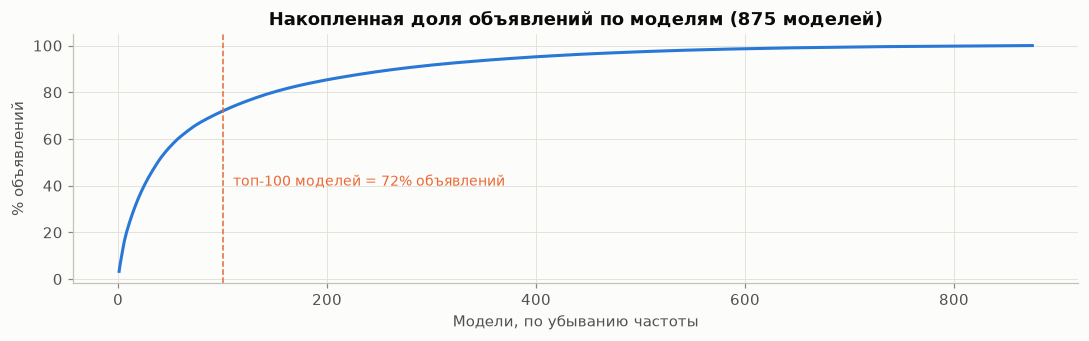

Моделей с < 10 объявлениями: 492 из 875


In [19]:
# Почему для «модели» нужен target encoding: длинный хвост редких значений
counts = X_feat["model"].value_counts()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(np.arange(1, len(counts) + 1), counts.cumsum() / counts.sum() * 100, color=viz.SERIES[0], linewidth=2)
ax.axvline(100, color=viz.SERIES[1], linestyle="--", linewidth=1)
ax.text(110, 40, f"топ-100 моделей = {counts.head(100).sum() / counts.sum():.0%} объявлений", color=viz.SERIES[1], fontsize=9)
ax.set(title=f"Накопленная доля объявлений по моделям ({len(counts)} моделей)", xlabel="Модели, по убыванию частоты", ylabel="% объявлений")
show(fig, "prep_model_cardinality")
print(f"Моделей с < 10 объявлениями: {(counts < 10).sum()} из {len(counts)}")

In [20]:
from sklearn.pipeline import Pipeline
from car_advisor.ml.models import ridge_preprocessor

# обучаем препроцессинг ТОЛЬКО на train (целевая — log цены, как у модели), применяем к test
prep = Pipeline([("features", FeatureBuilder()), ("prep", ridge_preprocessor())])
Z_train = pd.DataFrame(prep.fit_transform(X_train, np.log(y_train)), columns=prep.get_feature_names_out(), index=X_train.index)
Z_test = pd.DataFrame(prep.transform(X_test), columns=Z_train.columns, index=X_test.index)
print(f"9 признаков → {Z_train.shape[1]} колонок после кодирования. train {Z_train.shape}, test {Z_test.shape}")
print(Z_train.columns.str.split("__").str[0].value_counts().rename("колонок").to_string())

scaled = ["engine__engine_cc", "kmy__km_per_year"]
pd.DataFrame({"train: среднее": Z_train[scaled].mean(), "train: std": Z_train[scaled].std(),
              "test: среднее": Z_test[scaled].mean(), "test: std": Z_test[scaled].std()}).round(3)

9 признаков → 95 колонок после кодирования. train (25038, 95), test (6260, 95)
ohe       74
age       10
dist       8
te         1
engine     1
kmy        1


,train: среднее,train: std,test: среднее,test: std
engine__engine_cc,-0.0,1.0,-0.015,0.980
kmy__km_per_year,-0.0,1.0,0.009,1.011


In [21]:
# Target encoding: значение «модели» = сглаженное среднее log(цены) этой модели на train
te = prep.named_steps["prep"].named_transformers_["te"]
encoding = pd.Series(te.encodings_[0], index=te.categories_[0], name="TE ≈ log(€)")
example = encoding.loc[["Dacia Logan", "Volkswagen Golf", "Toyota Camry", "BMW X5", "Porsche Cayenne"]]
train_counts = FeatureBuilder().transform(X_train)["model"].value_counts()
pd.DataFrame({"TE ≈ log(€)": example.round(2), "≈ €": np.exp(example).round(-2), "объявлений в train": train_counts.reindex(example.index)})

,TE ≈ log(€),≈ €,объявлений в train
Dacia Logan,8.06,3200.0,363
Volkswagen Golf,8.36,4300.0,589
Toyota Camry,9.27,10600.0,121
BMW X5,9.60,14800.0,286
Porsche Cayenne,10.35,31200.0,109


**Вывод.** После препроцессинга 9 исходных признаков превращаются в числовую матрицу из 95 колонок (74 one-hot, 18 сплайновых, 3 числовых), полностью готовую для scikit-learn. Стандартизованные признаки на train имеют среднее 0 и std 1. На test они близки к этим значениям, но не равны в точности, и так и должно быть: параметры масштабирования взяты только из train. Target encoding превращает модель авто в одно число — сглаженную среднюю log-цену этой модели (Dacia Logan ≈ 3 200 €, Toyota Camry ≈ 10 600 €, Porsche Cayenne ≈ 31 000 €).

### 3.6 Защита от утечки данных (data leakage)

* Все **обучаемые** преобразования (кодировщики, масштабирование, сплайны) живут внутри `Pipeline`. При кросс-валидации они обучаются заново на каждом обучающем фолде и не видят валидационный.
* Target encoding внутри обучения использует **кросс-фиттинг**: значение для строки считается без её собственной цены.
* Отложенные «новые» объявления не участвуют ни в чём, кроме финальной проверки.
* Известное ограничение: правило «цена отличается от медианы марки/модели/года более чем в 3 раза» применяется ко всему датасету до разбиения. Оно затрагивает 312 строк (< 1%), в основном цены в леях. Это чистка явных ошибок, а не обучение, поэтому влияние на метрики минимально.
* Ещё одно ограничение очистки: дубликаты ищутся **до** исправления объёма двигателя. Поэтому в `listings` остаются 3 точных дубликата: после исправления (200 «см³» → 2000 см³, обнуление объёма у электромобиля) две публикации одной машины стали одинаковыми. Уберём их на следующем этапе; 3 строки из 31 298 на метрики практически не влияют.

Ещё один источник оптимизма — **почти-дубликаты**: строки test, которые совпадают со строкой train по всем 8 признакам автомобиля; цена при этом может отличаться.

In [22]:
# Почти-дубликаты: строка test совпадает со строкой train по всем 8 признакам автомобиля (цена может отличаться)
KEY = ["make", "model", "year", "style", "distance_km", "engine_cc", "fuel_type", "transmission"]
train_keys = set(X_train[KEY].itertuples(index=False, name=None))
near_dup = pd.Series([k in train_keys for k in X_test[KEY].itertuples(index=False, name=None)], index=X_test.index)
twin_price = pd.concat([X_train[KEY], y_train], axis=1).groupby(KEY)["price_eur"].median() \
    .reindex(pd.MultiIndex.from_frame(X_test.loc[near_dup, KEY])).to_numpy()
print(f"Почти-дубликатов в test: {near_dup.sum()} из {len(X_test):,} ({near_dup.mean():.1%})")
print(f"Разница цены с «двойником» из train (медиана): {np.median(np.abs(y_test[near_dup] / twin_price - 1)):.1%}")
print(f"Точных дубликатов в listings: {df.duplicated(subset=db.LISTING_COLUMNS).sum()}")

Почти-дубликатов в test: 256 из 6,260 (4.1%)
Разница цены с «двойником» из train (медиана): 5.7%
Точных дубликатов в listings: 3


**Вывод.** 256 строк test (4.1%) — почти-дубликаты: та же марка, модель, год, кузов, пробег до километра, объём, топливо и КПП, а цена отличается на 5.7% (медиана относительной разницы с медианной ценой «двойников» в train). Скорее всего, это одна и та же машина, которую продавец выложил повторно с новой ценой. Для такой строки модель на train уже видела почти правильный ответ, поэтому метрики на test могут быть **слегка завышены**. Насколько — проверяем в разделе 4: переобучаем модели без «двойников» в train и сравниваем на том же test. Случайное разбиение такие пары не разделяет.

На следующем этапе разбиение будет **по группам**: `GroupShuffleSplit` для train/test (и `GroupKFold` для кросс-валидации), группа — ключ из этих 8 признаков. Тогда все публикации одной машины попадут в одну часть.

## 4. Бейзлайн (бонус)

Прежде чем строить сложные модели, нужна точка отсчёта. Сравниваем три уровня (`car_advisor/ml/baseline.py`):
1. **Константа** — всегда медианная цена train. Модель, которая ничего не знает об автомобиле.
2. **Медиана похожих объявлений** — так оценивает цену человек без ML: смотрит медиану такой же модели того же возраста (если таких мало — той же модели, марки, всего рынка).
3. **Ridge-регрессия** на log(цены) с препроцессингом из раздела 3.5 — первая ML-модель.

Протокол тот же, что будет у основных моделей: 5-fold кросс-валидация на train, затем проверка на test.

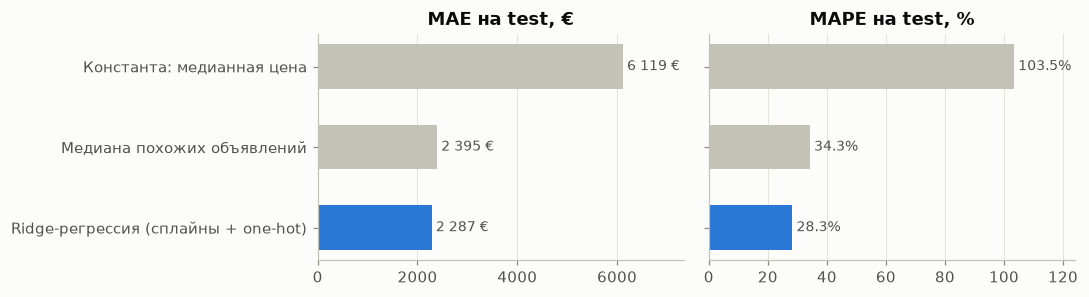

,"CV MAE, €",± std,"test MAE, €",MAPE,медиана APE,R²,доля ошибок ≤ 20%
title,,,,,,,
Константа: медианная цена,"5,988",115,"6,119",103.5%,53.1%,-0.073,20.1%
Медиана похожих объявлений,"2,439",42,"2,395",34.3%,15.4%,0.603,59.1%
Ridge-регрессия (сплайны + one-hot),"2,234",41,"2,287",28.3%,18.1%,0.742,54.6%


In [23]:
comparison, fitted = baseline.evaluate(X_train, X_test, y_train, y_test)
show(baseline.plot_baselines(comparison), "baseline_comparison")
table = comparison.set_index("title")[["cv_mae", "cv_mae_std", "test_mae", "test_mape", "test_medape", "test_r2", "test_within_20pct"]]
table.columns = ["CV MAE, €", "± std", "test MAE, €", "MAPE", "медиана APE", "R²", "доля ошибок ≤ 20%"]
table.style.format({"CV MAE, €": "{:,.0f}", "± std": "{:,.0f}", "test MAE, €": "{:,.0f}", "MAPE": "{:.1%}",
                    "медиана APE": "{:.1%}", "R²": "{:.3f}", "доля ошибок ≤ 20%": "{:.1%}"})

In [24]:
# Где Ridge ошибается сильнее всего: ошибка по ценовым сегментам на test
pred = fitted["ridge"].predict(X_test)
seg = pd.cut(y_test, [0, 3_000, 6_000, 10_000, 20_000, np.inf], labels=["< 3k €", "3–6k €", "6–10k €", "10–20k €", "> 20k €"])
errors = pd.DataFrame({"y": y_test, "abs": np.abs(pred - y_test), "ape": np.abs(pred - y_test) / y_test})
by_seg = errors.groupby(seg, observed=True).agg(объявлений=("y", "size"), MAE=("abs", "mean"), MAPE=("ape", "mean"),
                                                total=("abs", "sum"))
by_seg["доля всей ошибки"] = by_seg.pop("total") / errors["abs"].sum()
by_seg.style.format({"MAE": "{:,.0f} €", "MAPE": "{:.1%}", "доля всей ошибки": "{:.1%}"})

,объявлений,MAE,MAPE,доля всей ошибки
price_eur,,,,
< 3k €,1241,871 €,56.2%,7.5%
3–6k €,1575,"1,120 €",25.1%,12.3%
6–10k €,1492,"1,622 €",20.5%,16.9%
10–20k €,1367,"2,491 €",17.3%,23.8%
> 20k €,585,"9,653 €",23.9%,39.4%


In [25]:
# Почти-дубликаты (раздел 3.6): переобучаем модели без «двойников» test в train и сравниваем на том же test
test_keys = set(X_test.loc[near_dup, KEY].itertuples(index=False, name=None))
no_twins = ~pd.Series([k in test_keys for k in X_train[KEY].itertuples(index=False, name=None)], index=X_train.index)
print(f"Убираем из train «двойников»: {(~no_twins).sum()}; test тот же: {len(X_test):,} строк")
test_mae = comparison.set_index("name")["test_mae"]
for name, (title, make) in baseline.BASELINES.items():
    mae = np.abs(make().fit(X_train[no_twins], y_train[no_twins]).predict(X_test) - y_test).mean()
    print(f"  {title:38s} test MAE {test_mae[name]:6,.0f} € → без «двойников» в train {mae:6,.0f} €")

Убираем из train «двойников»: 291; test тот же: 6,260 строк
  Константа: медианная цена              test MAE  6,119 € → без «двойников» в train  6,119 €
  Медиана похожих объявлений             test MAE  2,395 € → без «двойников» в train  2,419 €


  Ridge-регрессия (сплайны + one-hot)    test MAE  2,287 € → без «двойников» в train  2,288 €


**Вывод.**
* Константа ошибается в среднем на ~6 100 € (MAPE ≈ 100%), R² ≈ 0. Это нижняя граница: любая модель обязана быть заметно лучше.
* «Медиана похожих объявлений» — сильный бейзлайн: MAE ≈ 2 400 €, 59% оценок в пределах ±20%.
* **Ridge — лучший по MAE (≈ 2 290 €), MAPE (28%) и R² (0.74)**, CV и test согласуются (2 234 € и 2 287 €), то есть переобучения нет. Но по доле точных оценок (55%) он *уступает* простой медиане. Линейная модель складывает эффекты признаков и не умеет учить **взаимодействия**: у премиальных и бюджетных марок разная скорость амортизации (Г4–Г6).
* Сильнее всего ошибки в дешёвом сегменте (< 3 000 €, MAPE ≈ 56%): там цена больше зависит от состояния, которого нет в данных.
* **Почему учим на log(цены), а модель выбираем по MAE в евро.** Логарифм выравнивает скошенную цену (Г1) и делает ошибку относительной, поэтому модель одинаково старается для дешёвых и дорогих машин. MAE в евро понятна бизнесу («ошибаемся в среднем на N €»), но это абсолютная ошибка, и её определяют дорогие машины: дороже 20 000 € — 9% строк test, а на них приходится **39% суммарной ошибки** Ridge (таблица выше). Поэтому рядом с MAE всегда смотрим **MAPE** и **долю оценок в ±20%**: это относительные ошибки, в них каждое объявление весит одинаково, независимо от цены.
* Почти-дубликаты (раздел 3.6) завышают метрики незначительно: если переобучить модели без 291 «двойника» в train, на том же test MAE Ridge 2 288 € вместо 2 287 €, у медианы похожих объявлений 2 419 € вместо 2 395 € (+1%: она сильнее всех опирается на точные совпадения). Порядок моделей не меняется.

**Цели для следующего этапа** (критерии из раздела 1): MAE на test ≤ **1 830 €** (−20% к Ridge), MAPE ≤ 25%, ≥ 60% оценок в пределах ±20%. Кандидаты: Random Forest, LightGBM, CatBoost.

## 5. Итоги этапа и план

**Сделано (≈30%):**
* Business Understanding: цель, пользователи, тип задачи (регрессия + рекомендация), метрики и критерии успеха;
* данные: открытый датасет → БД (SQLAlchemy) с журналом качества; 11 правил очистки;
* EDA: словарь признаков с типами и шкалами, пропуски (включая скрытые), выбросы, распределения, корреляции, 8 графиков с выводами;
* Data Preparation: очистка, стратегия пропусков, 3 новых признака, кодирование (one-hot + target encoding), масштабирование, сплайны, стратифицированное разбиение train/test + отложенные «новые» данные;
* бейзлайн: три уровня сравнения, лучшая первая модель — Ridge, MAE ≈ 2 290 €, MAPE 28%, R² 0.74.

**План оставшихся этапов** (сроки ориентировочные):

| № | Фаза CRISP-DM | Что делаем | Срок |
|---|---|---|---|
| 1 | Modeling | Random Forest, LightGBM, CatBoost против Ridge на 5-fold CV; выбор по MAE; подбор гиперпараметров (RandomizedSearchCV) | 17.10 – 08.11 |
| 2 | Evaluation | test + отложенные «новые» объявления; ошибки по сегментам; интервалы цены; Explainable AI: SHAP, permutation importance | 09.11 – 22.11 |
| 3 | Deployment: приложение | веб-приложение (Streamlit): ввод авто → оценка, интервал, SHAP-объяснение; подбор выгодных предложений; дашборд рынка | 23.11 – 06.12 |
| 4 | Deployment: AI-агент | агент с инструментами (поиск в БД, ML-модель, статистика рынка, отзывы NHTSA, курс НБМ) → рекомендация BUY / NEGOTIATE / VERIFY / AVOID | 07.12 – 20.12 |
| 5 | Deployment: автоматизация | n8n: рекомендация → письмо менеджеру → «Одобрить/Отклонить» → Google Sheets (human-in-the-loop) | 21.12 – 27.12 |
| 6 | Бонус + сдача | MLflow, Docker Compose, мониторинг дрейфа; итоговый отчёт и защита | 28.12 – сессия |